# Lab 1: matrix multiplication plots

Reads the bench CSVs in `results/` and writes the PNGs that `README.md` embeds.

- `results/sizes.csv`: every variant at every size. Serial variants ran with
  `OMP_NUM_THREADS=1`, parallel ones with 11 threads.
- `results/scaling.csv`: the parallel variants at n = 2048 and 4096 with
  1 to 11 threads.

Each configuration was measured in several independent runs; the time used
below is the minimum over all repetitions of all runs.

Re-run from the repository root with
`.venv/bin/jupyter nbconvert --to notebook --execute --inplace lab_1/plots.ipynb`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

RESULTS = Path("results")
ORDER = ["naive", "transposed", "blocked", "strassen",
         "blocked_omp", "simd", "simd_omp", "best"]
PARALLEL = ["blocked_omp", "simd_omp", "best"]
COLORS = dict(zip(ORDER, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                          "#e87ba4", "#008300", "#4a3aa7", "#e34948"]))

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "lines.markersize": 6,
})


def load(name):
    df = pd.read_csv(RESULTS / name)
    best = (df.groupby(["variant", "n", "threads"])
              .agg(min_s=("min_s", "min"), reps=("reps", "sum"))
              .reset_index())
    best["gflops"] = 2.0 * best["n"].astype(float) ** 3 / best["min_s"] * 1e-9
    return best


sizes = load("sizes.csv")
scaling = load("scaling.csv")

## Time vs size

In [2]:
times = (sizes.pivot(index="n", columns="variant", values="min_s")
              [[v for v in ORDER if v in set(sizes["variant"])]])
threads = sizes.groupby("variant")["threads"].first()
times.style.format("{:.6f}")

variant,naive,transposed,blocked,strassen,blocked_omp,simd,simd_omp,best
n,,,,,,,,
64,0.000108,0.000105,0.000070,0.000070,0.000087,0.000007,0.000117,0.000008
128,0.001175,0.001112,0.000567,0.000503,0.000318,0.000046,0.000120,0.000049
256,0.011312,0.010881,0.004722,0.003772,0.001276,0.000315,0.000172,0.000176
512,0.105610,0.104642,0.038715,0.026815,0.008218,0.002416,0.000530,0.000526
1024,0.955506,0.911477,0.312264,0.188505,0.050501,0.019123,0.003101,0.003116
2048,8.633143,7.713088,3.091669,1.330655,0.440155,0.153508,0.023336,0.023332
4096,205.987561,63.401546,23.033272,9.422493,3.324264,1.241911,0.187311,0.175975


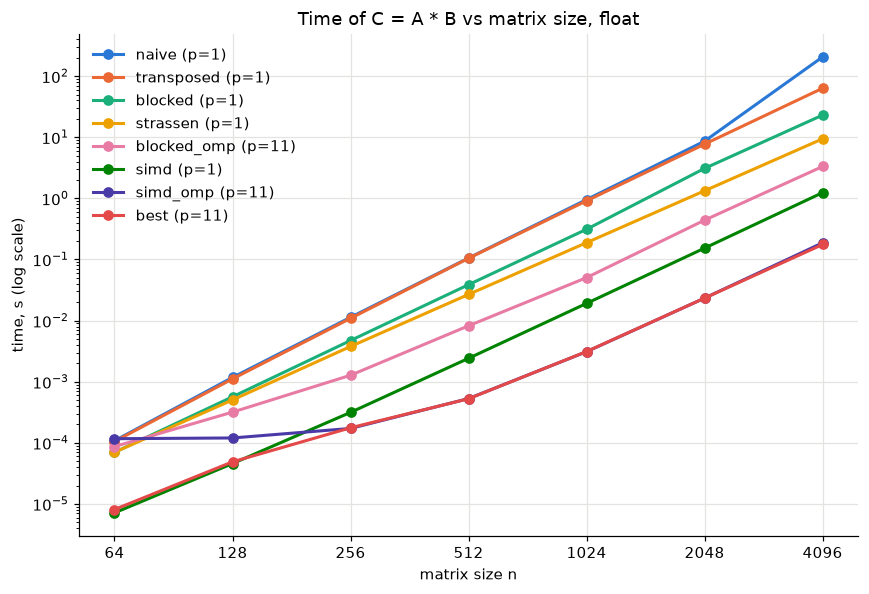

In [3]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for v in times.columns:
    s = times[v].dropna()
    ax.plot(s.index, s.values, marker="o", color=COLORS[v],
            label=f"{v} (p={threads[v]})")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(times.index, [str(n) for n in times.index])
ax.set_xlabel("matrix size n")
ax.set_ylabel("time, s (log scale)")
ax.set_title("Time of C = A * B vs matrix size, float")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "time_vs_size.png")

variant,naive,transposed,blocked,strassen,blocked_omp,simd,simd_omp,best
n,,,,,,,,
64,4.85,4.99,7.51,7.48,6.04,73.30,4.49,64.68
128,3.57,3.77,7.40,8.34,13.19,91.63,34.91,85.82
256,2.97,3.08,7.11,8.90,26.30,106.54,195.20,190.44
512,2.54,2.57,6.93,10.01,32.67,111.11,506.48,510.38
1024,2.25,2.36,6.88,11.39,42.52,112.30,692.49,689.20
2048,1.99,2.23,5.56,12.91,39.03,111.92,736.19,736.32
4096,0.67,2.17,5.97,14.59,41.34,110.67,733.75,781.01


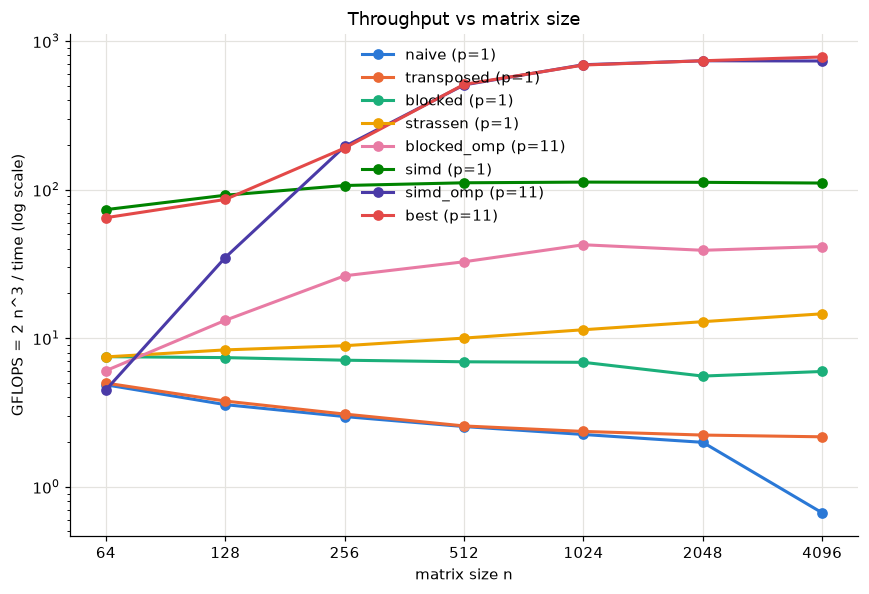

In [4]:
gflops = sizes.pivot(index="n", columns="variant", values="gflops")[times.columns]
fig, ax = plt.subplots(figsize=(8, 5.5))
for v in gflops.columns:
    s = gflops[v].dropna()
    ax.plot(s.index, s.values, marker="o", color=COLORS[v],
            label=f"{v} (p={threads[v]})")
ax.set_xscale("log", base=2)
ax.set_yscale("log")
ax.set_xticks(gflops.index, [str(n) for n in gflops.index])
ax.set_xlabel("matrix size n")
ax.set_ylabel("GFLOPS = 2 n^3 / time (log scale)")
ax.set_title("Throughput vs matrix size")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(RESULTS / "gflops_vs_size.png")
gflops.round(2)

## Speedup and efficiency

S(p) = T(1) / T(p) and E(p) = S(p) / p, where T(1) is the same variant run
with one thread.

In [5]:
t1 = scaling[scaling["threads"] == 1].set_index(["variant", "n"])["min_s"]
scaling["speedup"] = [t1[(v, n)] / t for v, n, t in
                      zip(scaling["variant"], scaling["n"], scaling["min_s"])]
scaling["efficiency"] = scaling["speedup"] / scaling["threads"]
table = scaling.pivot_table(index=["variant", "n"], columns="threads",
                            values=["min_s", "speedup", "efficiency"])
table.round(3)

efficiency                                      min_s  \
threads                  1      2      4      6      8      11      1    
variant     n                                                            
best        2048        1.0  0.970  0.941  0.829  0.708  0.593   0.152   
            4096        1.0  0.966  0.921  0.805  0.680  0.567   1.092   
blocked_omp 2048        1.0  0.905  0.903  0.794  0.746  0.624   3.090   
            4096        1.0  0.964  0.947  0.838  0.735  0.619  23.042   
simd_omp    2048        1.0  0.972  0.943  0.833  0.709  0.597   0.153   
            4096        1.0  0.977  0.954  0.842  0.727  0.606   1.240   

                                                     speedup                \
threads               2      4      6      8      11      1      2      4    
variant     n                                                                
best        2048   0.078  0.040  0.031  0.027  0.023     1.0  1.940  3.762   
            4096   0.565  0.297  0.226  0.201  0.175     1.0  1.932  3.682   
blocked_omp 2048   1.707  0.856  0.649  0.518  0.450     1.0  1.810  3.610   
            4096  11.955  6.082  4.583  3.917  3.383     1.0  1.927  3.788   
simd_omp    2048   0.079  0.040  0.031  0.027  0.023     1.0  1.943  3.773   
            4096   0.635  0.325  0.246  0.213  0.186     1.0  1.954  3.815   

                                       
threads              6      8      11  
variant     n                          
best        2048  4.974  5.664  6.527  
            4096  4.830  5.437  6.234  
blocked_omp 2048  4.764  5.970  6.865  
            4096  5.027  5.882  6.812  
simd_omp    2048  4.996  5.673  6.569  
            4096  5.049  5.813  6.665

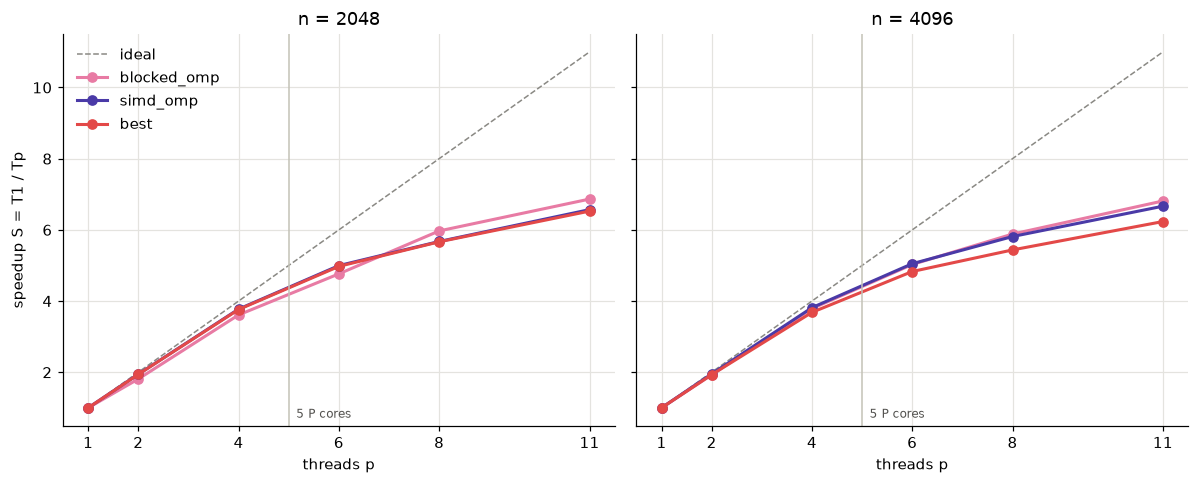

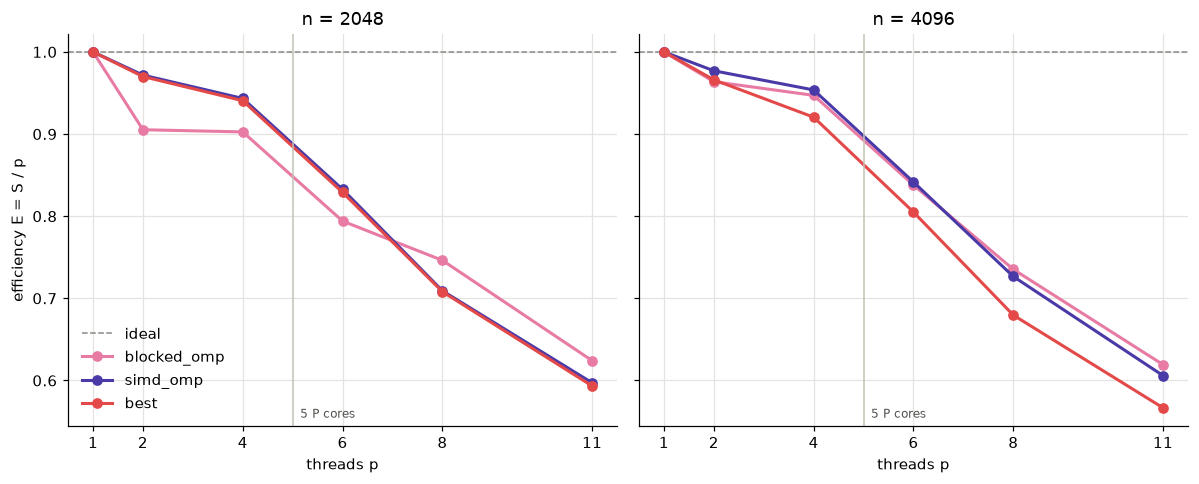

In [6]:
ps = sorted(scaling["threads"].unique())
for metric, ylabel, fname in [("speedup", "speedup S = T1 / Tp", "speedup.png"),
                              ("efficiency", "efficiency E = S / p",
                               "efficiency.png")]:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
    for ax, n in zip(axes, sorted(scaling["n"].unique())):
        if metric == "speedup":
            ax.plot(ps, ps, color="#8a8984", linestyle="--", linewidth=1,
                    label="ideal")
        else:
            ax.axhline(1.0, color="#8a8984", linestyle="--", linewidth=1,
                       label="ideal")
        for v in PARALLEL:
            s = scaling[(scaling["variant"] == v) & (scaling["n"] == n)]
            s = s.sort_values("threads")
            ax.plot(s["threads"], s[metric], marker="o", color=COLORS[v],
                    label=v)
        ax.axvline(5, color="#c3c2b7", linewidth=1)
        ax.text(5.15, 0.02, "5 P cores", transform=ax.get_xaxis_transform(),
                color="#52514e", fontsize=8)
        ax.set_xticks(ps)
        ax.set_xlabel("threads p")
        ax.set_title(f"n = {n}")
    axes[0].set_ylabel(ylabel)
    axes[0].legend(frameon=False)
    fig.tight_layout()
    fig.savefig(RESULTS / fname)